# A machine learning approach to volatility forecasting: replication and extension to 2015–2026

**Paper:** Christensen, Siggaard & Veliyev (2022/2023), *A machine learning approach to volatility forecasting*, Journal of Financial Econometrics (arXiv:2601.13014).

**Research question.** The paper shows (DJIA stocks, 2001–2017) that off-the-shelf ML (regularization, random forest, neural nets) beats the HAR model family in forecasting realized variance, and that the edge grows with the information set and the forecast horizon. **Does this result hold out-of-sample in a new, non-overlapping market regime (2015–2026), using only open data?**

**Data.** 5-minute realized measures for the Dow 30 from **VOLARE** (Cipollini et al., 2026, arXiv:2602.19732, https://volare.unime.it), open-access and built from cleaned tick data, plus public macro series (FRED, Philadelphia Fed, Yahoo Finance).

**Design (as in the paper).** 70/10/20 train/validation/test split; HAR, HAR-X, LogHAR, LevHAR, SHAR, HARQ vs. ridge, lasso, elastic net, random forest, gradient boosting, neural nets; information sets $\mathcal M_{HAR}$ (RV lags only) and $\mathcal M_{ALL}$ (+ extra predictors); horizons 1, 5, 22 days; relative MSE + Diebold–Mariano tests; ALE-based variable importance.

All code lives in `volml.py`; this notebook runs it and produces every table and figure.

In [3]:
# !pip install pandas numpy scipy scikit-learn matplotlib joblib openpyxl yfinance pyarrow
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import volml as V

QUICK = True        # True: 8 stocks + lighter models for a first pass (~10-20 min). False: full run.
DRY_RUN = False     # True: simulated data, no downloads needed (pipeline test only)

# Data source: "volare" (preferred) | "alpaca" (5-min bars, 2016+) | "yahoo" (daily range proxy, 2001+) | "binance" (crypto)
# Fallback files are created with:  python fetch_data.py alpaca|yahoo|binance  (see README)
DATA_SOURCE = "alpaca"
PATHS = {"volare": "data/volare", "alpaca": "data/alpaca/realized.csv",
         "yahoo": "data/yahoo/realized.csv", "binance": "data/binance/realized.csv"}
cfg = V.Config(volare_path=PATHS[DATA_SOURCE])
if DATA_SOURCE == "yahoo":
    cfg.start = "2001-01-01"      # paper window + extension; set cfg.end = "2017-12-31" to mimic the paper sample
if QUICK and DATA_SOURCE != "binance":
    cfg.symbols = ["AAPL", "MSFT", "JPM", "KO", "BA", "CVX", "WMT", "IBM"]
    cfg.rf_trees, cfg.nn_seeds, cfg.nn_top, cfg.refit_trees = 200, 5, 3, 126
os.makedirs(cfg.results_dir, exist_ok=True)
cfg

Config(volare_path='data/alpaca/realized.csv', symbols=['AAPL', 'MSFT', 'JPM', 'KO', 'BA', 'CVX', 'WMT', 'IBM'], start='2015-01-01', end=None, horizons=(1, 5, 22), datasets=('M_HAR', 'M_ALL'), train_frac=0.7, val_frac=0.1, refit_linear=1, refit_reg=22, refit_trees=126, models=('HAR', 'HAR-X', 'LogHAR', 'LevHAR', 'SHAR', 'HARQ', 'RR', 'LA', 'EN', 'RF', 'GB', 'NN'), rf_trees=200, rf_min_leaf=5, nn_archs=((4, 2),), nn_seeds=5, nn_top=3, nn_max_epochs=500, nn_patience=50, nn_lr=0.001, nn_l2=0.0001, nn_batch=32, n_jobs=-1, cache_dir='data/cache', results_dir='results', offline_macro=False, ea_file=None, iv_file=None, seed=42)

## 1. Data

**If VOLARE access is pending:** run `python fetch_data.py alpaca --key ... --secret ...` (free Alpaca paper account, true 5-min RV from 2016) or `python fetch_data.py yahoo` (no account, daily Garman–Klass proxy from 2001) and set `DATA_SOURCE` above accordingly. With Yahoo, HARQ and SHAR are skipped automatically (no intraday data).

**VOLARE (realized measures).** Go to https://volare.unime.it → *Download Data* → asset type *Stocks*, measure set with the 5-minute measures (`rv5`, `rq5`, `rsp5`, `rsn5`) plus open/close/volume. Put the downloaded file(s) into `data/volare/`. The loader matches column names case-insensitively and prints what it found; if a name differs, add it to `_ALIASES` in `volml.py`.

**Macro (downloaded automatically, cached in `data/cache/`).** VIX (FRED `VIXCLS`), economic policy uncertainty (FRED `USEPUINDXD`), 3-month T-bill (FRED `DTB3`, first-differenced), Hang Seng squared log return (Yahoo `^HSI`), ADS business conditions index (Philadelphia Fed).

**Firm-level extras.** Momentum (`M1W`, 5-day sum of open-to-close returns) and dollar volume (`DVOL`) are built from VOLARE. Model-free implied volatility (OptionMetrics) and earnings dates are not openly available: they can be added through `cfg.iv_file` / `cfg.ea_file` (CSV) if you get them, e.g. implied vols from LSEG Workspace.

In [4]:
if DRY_RUN:
    panel, macro = V.simulate_panel(n_stocks=6, n_days=2800)
    panel = panel.rename(columns={"rv5": "rv", "rq5": "rq", "rsp5": "rsp", "rsn5": "rsn"})
    panel[["rv", "rsp", "rsn"]] *= 1e4; panel["rq"] *= 1e8
    cfg.symbols = sorted(panel.symbol.unique())
else:
    panel = V.load_volare(cfg.volare_path, symbols=None if DATA_SOURCE == "binance" else cfg.symbols)
    if DATA_SOURCE == "binance":
        cfg.symbols = sorted(panel.symbol.unique())
    macro = V.load_macro(cfg)

ea = pd.read_csv(cfg.ea_file, parse_dates=["date"]) if cfg.ea_file else None
iv = pd.read_csv(cfg.iv_file, parse_dates=["date"]) if cfg.iv_file else None
panel.groupby("symbol")["date"].agg(["min", "max", "count"]).head(30)

VOLARE: 8 symbols, 2016-01-04 -> 2026-10-15, columns: ['date', 'symbol', 'rv', 'rq', 'rsp', 'rsn', 'open', 'close', 'volume']
macro VIX: 1990-01-02 -> 2026-10-15
macro EPU: 1985-01-01 -> 2026-10-15
macro US3M: 1954-01-04 -> 2026-10-15
macro HSI: 2014-01-03 -> 2026-10-16
macro ADS: 1960-03-01 -> 2026-10-10


,min,max,count
symbol,,,
AAPL,2016-01-04,2026-10-15,2710
BA,2016-01-04,2026-10-15,2708
CVX,2016-01-04,2026-10-15,2708
IBM,2016-01-04,2026-10-15,2709
JPM,2016-01-04,2026-10-15,2709
KO,2016-01-04,2026-10-15,2709
MSFT,2016-01-04,2026-10-15,2710
WMT,2016-01-04,2026-10-15,2708


### Descriptive statistics (cf. paper Table 1; realized volatility annualized in %)

In [5]:
ann = lambda x: np.sqrt(252 * x)     # RV is stored in (daily %)^2
desc = []
for s, g in panel.groupby("symbol"):
    f = V.build_features(g, macro, cfg)
    t = pd.DataFrame({"RVD": ann(f["RVD"]), "RVW": ann(f["RVW"]), "RVM": ann(f["RVM"])})
    for c in V.extra_cols(f):
        t[c] = f[c]
    desc.append(t.describe().T.assign(skew=t.skew(), kurt=t.kurt() + 3))
desc = pd.concat(desc).groupby(level=0).mean()[["mean", "50%", "max", "min", "std", "skew", "kurt"]]
desc.round(2)

,mean,50%,max,min,std,skew,kurt
ADS,-0.22,-0.12,9.64,-26.64,2.77,-5.98,56.26
DVOL,0.00,-0.01,1.94,-1.21,0.32,0.49,5.04
EPU,176.26,126.85,1026.38,4.05,139.60,1.84,7.00
HSI,1.89,0.56,201.16,0.00,5.69,19.80,605.04
M1W,0.11,0.20,15.05,-18.46,2.85,-0.32,7.74
RVD,19.20,16.84,148.82,5.55,10.66,4.37,38.14
RVM,20.07,18.17,89.03,9.57,8.85,3.79,26.16
RVW,19.69,17.60,122.53,7.59,9.74,4.35,36.10
US3M,-0.00,0.00,0.17,-0.22,0.02,-1.52,20.66
VIX,18.46,16.76,82.69,9.14,7.12,2.63,16.37


## 2. Forecasting (rolling out-of-sample, all models, both information sets, h = 1, 5, 22)

In [6]:
pkl = os.path.join(cfg.results_dir, f"preds_{'quick' if QUICK else 'full'}.pkl")
if os.path.exists(pkl):
    preds, info = pd.read_pickle(pkl)
else:
    t0 = time.time()
    preds, info = V.run_all(cfg, panel, macro, ea, iv)
    pd.to_pickle((preds, info), pkl)
    print(f"done in {(time.time() - t0) / 60:.1f} min")
s0 = next(iter(info))
print("sample split:", info[s0][("M_HAR", 1)]["n"])
print("tuned hyperparameters (example):", {k: v for k, v in info[s0][("M_ALL", 1)].items() if k != "n"})

train <= 2023-07-27 < val <= 2024-08-22 < test


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   8 | elapsed:  3.0min remaining:  5.0min
[Parallel(n_jobs=-1)]: Done   5 out of   8 | elapsed:  3.1min remaining:  1.8min


done in 3.2 min
sample split: {'train': 1881, 'val': 270, 'test': 537, 'test_start': '2024-08-23', 'test_end': '2026-10-14'}
tuned hyperparameters (example): {'RR': {'alpha': np.float64(888.6238162743407), 'l1_ratio': None}, 'LA': {'alpha': np.float64(0.05878016072274912), 'l1_ratio': None}, 'EN': {'alpha': np.float64(0.38566204211634725), 'l1_ratio': 0.1}, 'GB': {'depth': 2, 'lr': 0.1, 'trees': 200}}


[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:  3.2min finished


## 3. Main results: relative MSE vs. HAR (cf. paper Tables 2–7)

Entries are cross-sectional averages of MSE(model)/MSE(HAR); < 1 means the model beats the HAR. Stars: one-sided Diebold–Mariano test (model better than HAR) rejected for more than 50% of stocks at 10% (\*), 5% (\*\*), 1% (\*\*\*). The paper's numbers are shown next to ours.

In [7]:
# HAR rows of the paper's Tables 2-7 (NN2_ens here = best 5 of 10 nets; paper NN2^10 = best 10 of 100)
PAPER = {
 ("M_HAR", 1):  dict(LogHAR=.995, LevHAR=1.073, SHAR=1.009, HARQ=1.059, RR=1.000, LA=1.003, EN=.999, BG=1.147, RF=1.020, GB=1.054, NN2_1=.966, NN2_ens=.958),
 ("M_ALL", 1):  {"HAR-X": .966, "LogHAR": .901, "LevHAR": 1.003, "SHAR": 1.080, "HARQ": 1.289, "RR": .919, "LA": .936, "EN": .916, "BG": .961, "RF": .901, "GB": .962, "NN2_1": .893, "NN2_ens": .885},
 ("M_HAR", 5):  dict(LogHAR=1.091, LevHAR=1.089, SHAR=.937, HARQ=1.043, RR=1.019, LA=1.024, EN=1.019, BG=1.056, RF=.959, GB=1.164, NN2_1=.947, NN2_ens=.937),
 ("M_ALL", 5):  {"HAR-X": 1.037, "LogHAR": .970, "LevHAR": 1.076, "SHAR": .913, "HARQ": 1.459, "RR": .954, "LA": .958, "EN": .925, "BG": .840, "RF": .796, "GB": .930, "NN2_1": .865, "NN2_ens": .846},
 ("M_HAR", 22): dict(LogHAR=1.052, LevHAR=1.030, SHAR=1.034, HARQ=.994, RR=1.100, LA=1.107, EN=1.111, BG=1.171, RF=1.019, GB=1.219, NN2_1=.989, NN2_ens=.958),
 ("M_ALL", 22): {"HAR-X": 1.290, "LogHAR": .919, "LevHAR": 1.328, "SHAR": 1.312, "HARQ": 1.569, "RR": 1.111, "LA": 1.378, "EN": 1.107, "BG": .621, "RF": .604, "GB": .829, "NN2_1": .816, "NN2_ens": .786},
}
summary = {}
for ds in cfg.datasets:
    for h in cfg.horizons:
        ratio, txt = V.relative_table(preds, ds, h)
        txt.to_csv(f"{cfg.results_dir}/table_{ds}_h{h}.csv")       # full pairwise matrix
        summary[(ds, f"h={h}", "ours")] = txt.loc["HAR"]
        summary[(ds, f"h={h}", "paper")] = pd.Series(PAPER[(ds, h)]).map("{:.3f}".format)
summary = pd.DataFrame(summary).drop(index="HAR", errors="ignore").fillna("")
summary.to_csv(f"{cfg.results_dir}/summary_vs_paper.csv")
summary

M_HAR                                        M_ALL                \
           h=1            h=5          h=22             h=1           h=5   
          ours  paper    ours  paper   ours  paper     ours  paper   ours   
BG              1.147          1.056         1.171           0.961          
EN       0.966  0.999   0.890  1.019  0.985  1.111   0.917*  0.916  0.837   
GB       1.324  1.054   1.874  1.164  2.939  1.219    0.882  0.962  1.670   
HAR-X                                                 0.929  0.966  1.050   
HARQ     1.005  1.059   1.142  1.043  1.286  0.994    0.937  1.289  1.106   
LA       0.980  1.003   0.971  1.024  1.011  1.107  0.925**  0.936  0.878   
LevHAR   0.999  1.073   1.043  1.089  1.036  1.030    0.939  1.003  1.060   
LogHAR   0.924  0.995  0.820*  1.091  0.804  1.052   0.894*  0.901  0.818   
NN2_1    1.078  0.966   1.037  0.947  1.183  0.989    0.992  0.893  0.846   
NN2_ens  0.951  0.958   0.920  0.937  1.078  0.958    0.929  0.885  1.013   
RF       1.044  1.020   1.319  0.959  2.191  1.019   0.867*  0.901  0.955   
RR       0.959  1.000   0.890  1.019  0.959  1.100    0.945  0.919  0.849   
SHAR     1.026  1.009   1.040  0.937  1.031  1.034    0.948  1.080  1.067   

                              
                 h=22         
         paper   ours  paper  
BG       0.840         0.621  
EN       0.925  0.985  1.107  
GB       0.930  0.958  0.829  
HAR-X    1.037  1.360  1.290  
HARQ     1.459  1.386  1.569  
LA       0.958  0.989  1.378  
LevHAR   1.076  1.369  1.328  
LogHAR   0.970  0.863  0.919  
NN2_1    0.865  0.902  0.816  
NN2_ens  0.846  0.877  0.786  
RF       0.796  1.189  0.604  
RR       0.954  1.014  1.111  
SHAR     0.913  1.371  1.312

Full pairwise matrix (paper layout: row = benchmark, column = model), example $\mathcal M_{ALL}$, h = 1:

In [8]:
V.relative_table(preds, "M_ALL", 1)[1]

,HAR,HAR-X,LogHAR,LevHAR,SHAR,HARQ,RR,LA,EN,RF,GB,NN2_1,NN2_ens
HAR,-,0.929,0.894*,0.939,0.948,0.937,0.945,0.925**,0.917*,0.867*,0.882,0.992,0.929
HAR-X,1.079,-,0.963,1.011,1.022,1.009,1.019,0.997,0.989,0.934,0.954,1.070,0.999
LogHAR,1.135,1.053,-,1.059,1.072,1.060,1.068,1.048,1.038,0.978,0.998,1.119,1.045
LevHAR,1.071,0.992,0.950,-,1.012,0.999,1.010,0.990,0.981,0.927,0.945,1.063,0.993
SHAR,1.057,0.980,0.941,0.989,-,0.989,0.998,0.977,0.969,0.916,0.929,1.049,0.982
HARQ,1.072,0.994,0.954,1.002,1.014,-,1.011,0.991,0.983,0.929,0.949,1.066,0.996
RR,1.061,0.984,0.943**,0.993,1.004,0.992,-,0.980,0.971,0.918,0.939,1.050,0.980
LA,1.083,1.005,0.967,1.016,1.026,1.015,1.023,-,0.992,0.936,0.950,1.071,1.000
EN,1.093,1.013,0.973**,1.024,1.035,1.023,1.031,1.009,-,0.944,0.963,1.079,1.007
RF,1.167,1.082,1.036,1.093,1.105,1.093,1.101,1.075,1.066,-,1.013,1.145,1.066


### Robustness: QLIKE loss (robust to noise in the RV proxy, Patton 2011)

In [9]:
ql = {(ds, f"h={h}"): V.relative_table(preds, ds, h, loss="qlike")[1].loc["HAR"]
      for ds in cfg.datasets for h in cfg.horizons}
pd.DataFrame(ql).drop(index="HAR").fillna("")

M_HAR                 M_ALL              
           h=1    h=5   h=22     h=1    h=5   h=22
EN       0.983  0.980  1.053   1.001  0.986  1.171
GB       1.045  1.030  1.145   1.064  1.019  1.218
HAR-X                          3.012  6.950  2.938
HARQ     1.110  1.185  1.113   2.058  2.345  2.100
LA       1.000  1.052  1.070   1.000  1.029  1.153
LevHAR   1.505  1.579  1.062   3.248  3.740  2.907
LogHAR   0.971  0.930  0.866  0.930*  0.927  0.945
NN2_1    1.070  1.550  2.217   1.187  1.120  1.151
NN2_ens  0.990  1.267  1.503   1.354  1.240  1.256
RF       1.030  1.038  1.117  0.949*  0.982  1.056
RR       0.978  0.973  1.045   1.078  1.049  1.287
SHAR     1.128  1.021  1.005   2.059  5.037  2.531

## 4. Cross-section of relative MSE (cf. paper Figure 3)

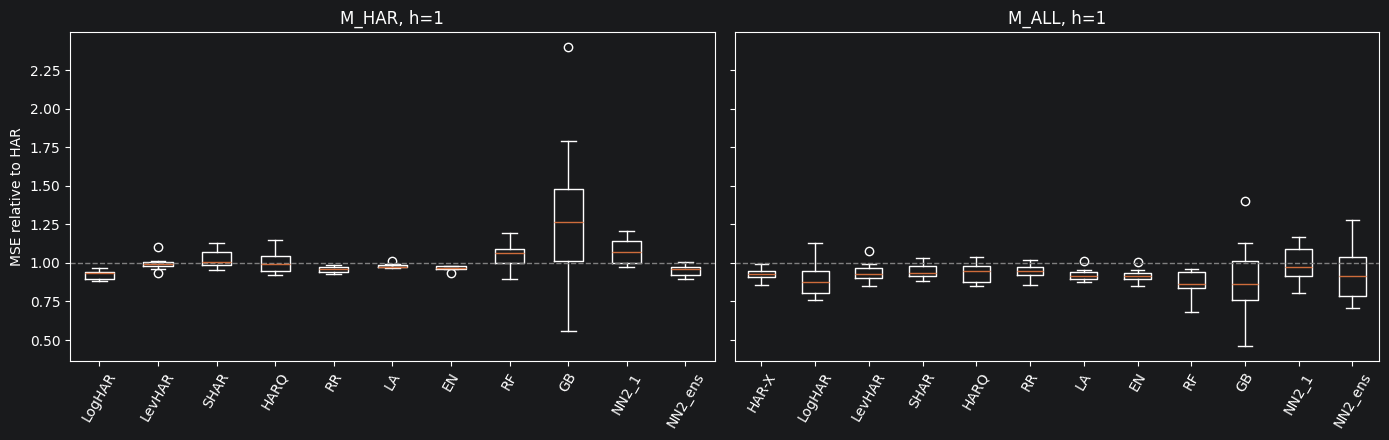

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, ds in zip(axes, cfg.datasets):
    R = V.per_stock_relative(preds, ds, 1).drop(columns="HAR")
    ax.boxplot(R.values, tick_labels=R.columns)
    ax.axhline(1, color="grey", lw=1, ls="--"); ax.set_title(f"{ds}, h=1"); ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("MSE relative to HAR")
plt.tight_layout(); plt.savefig(f"{cfg.results_dir}/fig3_boxplot.png", dpi=200); plt.show()

## 5. Accuracy across the volatility distribution (cf. paper Figure 5)

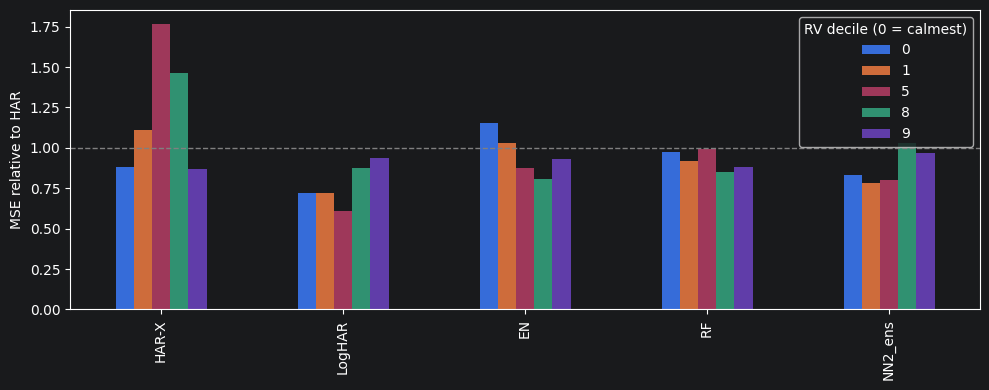

,HAR-X,LogHAR,EN,RF,NN2_ens
decile,,,,,
0,0.884,0.721,1.153,0.972,0.829
1,1.107,0.718,1.027,0.916,0.784
2,1.184,0.749,1.093,1.008,0.865
3,1.211,0.632,1.000,1.038,0.764
4,1.474,0.676,0.997,0.997,0.826
5,1.765,0.607,0.876,0.993,0.801
6,1.655,0.604,0.910,0.819,0.673
7,1.541,0.719,0.802,0.806,0.763
8,1.463,0.876,0.807,0.849,1.028


In [11]:
best_nn = [c for c in preds[s0][("M_ALL", 1)].columns if c.endswith("_ens")][0]
dec = V.decile_table(preds, "M_ALL", 1, models=["HAR-X", "LogHAR", "EN", "RF", best_nn])
ax = dec.loc[[0, 1, 5, 8, 9]].T.plot.bar(figsize=(10, 4)); ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_ylabel("MSE relative to HAR"); ax.legend(title="RV decile (0 = calmest)")
plt.tight_layout(); plt.savefig(f"{cfg.results_dir}/fig5_deciles.png", dpi=200); plt.show()
dec.round(3)

## 6. Opening the black box: ALE and variable importance (cf. paper Figures 6–7)

Models are fitted on the initial training set ($\mathcal M_{ALL}$, h = 1); importance = standard deviation of the centered accumulated local effect, normalized to sum to one, averaged across stocks.

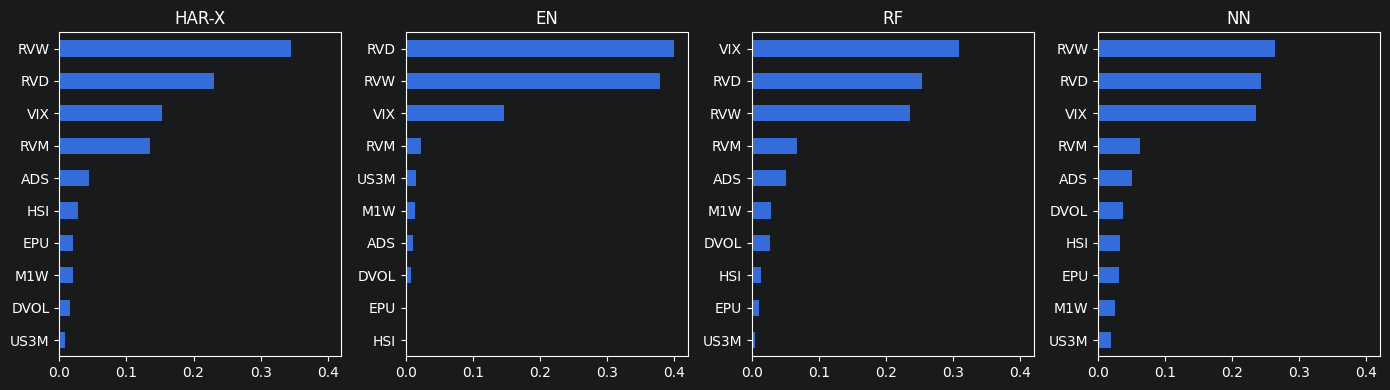

,HAR-X,EN,RF,NN
ADS,0.044,0.010,0.051,0.050
DVOL,0.016,0.009,0.026,0.037
EPU,0.020,0.002,0.011,0.031
HSI,0.027,0.001,0.013,0.033
M1W,0.020,0.014,0.029,0.025
RVD,0.231,0.400,0.253,0.242
RVM,0.135,0.024,0.068,0.062
RVW,0.346,0.379,0.236,0.264
US3M,0.009,0.016,0.005,0.020
VIX,0.153,0.146,0.309,0.235


In [12]:
d_tr, d_va = V.split_dates(panel[panel.date >= cfg.start], cfg)
vi_syms = cfg.symbols[:8]                       # VI is the slowest part; 8 stocks are enough for the figure
vis, fitted_aapl = [], None
for s in vi_syms:
    vi, fitted, tr = V.vi_for_stock(panel[panel.symbol == s], macro, cfg, d_tr, d_va)
    vis.append(vi)
    if s == vi_syms[0]:
        fitted_aapl, tr_aapl = fitted, tr
VI = sum(vis) / len(vis)
fig, axes = plt.subplots(1, VI.shape[1], figsize=(14, 4), sharex=True)
for ax, m in zip(axes, VI.columns):
    VI[m].sort_values().plot.barh(ax=ax); ax.set_title(m)
plt.tight_layout(); plt.savefig(f"{cfg.results_dir}/fig7_variable_importance.png", dpi=200); plt.show()
VI.round(3)

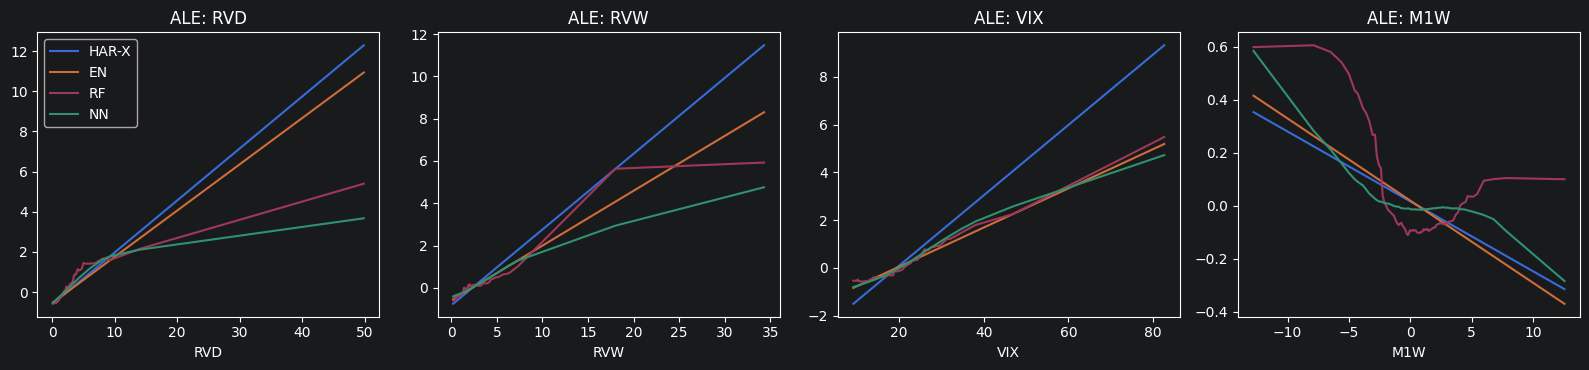

In [13]:
# ALE curves for the first stock (paper Figure 6 uses Apple)
cols = [c for c in ["RVD", "RVW", "VIX", "M1W"] if c in tr_aapl]
fig, axes = plt.subplots(1, len(cols), figsize=(16, 3.8))
for ax, c in zip(axes, cols):
    for name, m in fitted_aapl.items():
        e, a, _ = V.ale(m, tr_aapl, c)
        ax.plot(e, a, label=name)
    ax.set_title(f"ALE: {c}"); ax.set_xlabel(c)
axes[0].legend(); plt.tight_layout(); plt.savefig(f"{cfg.results_dir}/fig6_ale.png", dpi=200); plt.show()

## 7. Deviations from the original paper (state these on a slide)

| Paper | This replication | Why |
|---|---|---|
| NYSE TAQ, 29 DJIA stocks, 2001–2017 | VOLARE 5-min RV, Dow 30, 2015–latest | TAQ is not available to us; VOLARE is open and built from cleaned tick data with the same 5-min RV estimator |
| Model-free IV per stock (OptionMetrics), earnings dummy | Omitted by default (optional CSV hooks); VIX keeps the market-implied-vol channel | Not openly available |
| Tuning and RF/GB re-estimated daily | OLS daily; regularization every 22 days, trees every 63 days (configurable) | Compute budget on laptops; hyperparameters tuned once on the validation block |
| NN: L-ReLU, dropout, 100 seeds → best 10 | scikit-learn MLP, ReLU, L2 + early stopping, 10 seeds → best 5 | Paper reports ReLU makes no material difference (fn. 7) |
| Adaptive / post lasso, bagging, MCS, VaR | Not run by default (BG available via `cfg.models`) | Scope for one week |

Additional: QLIKE as a second loss function; explicit no-look-ahead rule for multi-day targets.